# Detection Visualization
Draw bounding boxes for detections from pg2gw logs on image coordinate system

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from datetime import datetime

In [2]:
# Configuration
IMAGE_WIDTH = 320
IMAGE_HEIGHT = 240

# Detection type colors
COLORS = {
    'detection': 'green',           # Regular detections
    'filtered_confidence': 'blue',  # Filtered by confidence
    'filtered_novelty': 'red'       # Filtered by novelty (GMM)
}

# Sensor IDs
SENSOR_IDS = [
    "6000000-2000-000003-2550",
    "6000000-2000-000009-2550"
]

# Input/Output paths
data_dir = Path("2025-12-19_10-50-09/pg2gw")
output_base_dir = Path("2025-12-19_10-50-09/visualizations")

In [3]:
# Load detection data for both sensors
sensor_data = {}

for sensor_id in SENSOR_IDS:
    json_file = data_dir / f"{sensor_id}_detections.json"
    if json_file.exists():
        with open(json_file, 'r') as f:
            sensor_data[sensor_id] = json.load(f)
        print(f"Loaded {len(sensor_data[sensor_id])} timestamps for {sensor_id}")
    else:
        print(f"Warning: {json_file} not found")
        sensor_data[sensor_id] = {}

Loaded 434 timestamps for 6000000-2000-000003-2550
Loaded 906 timestamps for 6000000-2000-000009-2550


In [4]:
def draw_detections(timestamp, detections, sensor_id, save_path):
    """
    Draw detection bounding boxes on image coordinate system.
    
    Args:
        timestamp: ISO format timestamp string
        detections: List of detection dictionaries
        sensor_id: Sensor identifier
        save_path: Path to save the image
    """
    fig, ax = plt.subplots(figsize=(12, 9))
    
    # Set up image coordinate system (origin at top-left)
    ax.set_xlim(0, IMAGE_WIDTH)
    ax.set_ylim(IMAGE_HEIGHT, 0)  # Inverted Y-axis for image coordinates
    ax.set_aspect('equal')
    
    # Set labels and grid
    ax.set_xlabel('X (pixels)', fontsize=12)
    ax.set_ylabel('Y (pixels)', fontsize=12)
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    
    # Set title with timestamp and sensor info
    ax.set_title(f'{timestamp}\nSensor: {sensor_id}', fontsize=14, fontweight='bold')
    
    # Draw background rectangle to represent image area
    bg_rect = patches.Rectangle((0, 0), IMAGE_WIDTH, IMAGE_HEIGHT, 
                                linewidth=2, edgecolor='black', 
                                facecolor='lightgray', alpha=0.1)
    ax.add_patch(bg_rect)
    
    # Draw each detection
    for detection in detections:
        det_type = detection['type']
        box = detection['box']
        color = COLORS.get(det_type, 'yellow')
        
        # Create rectangle patch
        rect = patches.Rectangle(
            (box['x'], box['y']), 
            box['w'], 
            box['h'],
            linewidth=2, 
            edgecolor=color, 
            facecolor='none',
            alpha=0.8
        )
        ax.add_patch(rect)
        
        # Add confidence label if available
        if 'confidence' in detection:
            conf = detection['confidence']
            label_x = box['x'] + box['w'] / 2
            label_y = box['y'] - 5
            ax.text(label_x, label_y, f'{conf:.2f}', 
                   color=color, fontsize=9, fontweight='bold',
                   ha='center', va='bottom',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
    
    # Create legend
    legend_elements = [
        patches.Patch(facecolor='none', edgecolor='green', linewidth=2, label='Regular Detection'),
        patches.Patch(facecolor='none', edgecolor='blue', linewidth=2, label='Filtered (Confidence)'),
        patches.Patch(facecolor='none', edgecolor='red', linewidth=2, label='Filtered (Novelty/GMM)')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    # Add detection count info
    type_counts = {}
    for det in detections:
        det_type = det['type']
        type_counts[det_type] = type_counts.get(det_type, 0) + 1
    
    info_text = f"Total: {len(detections)}\n"
    info_text += f"Regular: {type_counts.get('detection', 0)}\n"
    info_text += f"Low Conf: {type_counts.get('filtered_confidence', 0)}\n"
    info_text += f"Novelty: {type_counts.get('filtered_novelty', 0)}"
    
    ax.text(0.02, 0.98, info_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    
    return len(detections)

In [5]:
def timestamp_to_filename(timestamp_str):
    """
    Convert ISO timestamp to filename-safe format.
    Example: 2025-12-18T14:45:44 -> 2025-12-18_14-45-44
    """
    return timestamp_str.replace(':', '-').replace('T', '_')

In [6]:
# Generate visualizations for all sensors
total_images = 0

for sensor_id, timestamps_data in sensor_data.items():
    if not timestamps_data:
        print(f"No data for {sensor_id}, skipping...")
        continue
    
    # Create output directory for this sensor
    output_dir = output_base_dir / sensor_id
    output_dir.mkdir(parents=True, exist_ok=True)
    
    print(f"\nProcessing {sensor_id}...")
    print(f"Output directory: {output_dir}")
    
    sensor_images = 0
    
    for timestamp, detections in timestamps_data.items():
        if not detections:
            continue
        
        # Create filename from timestamp
        filename = timestamp_to_filename(timestamp) + '.png'
        save_path = output_dir / filename
        
        # Draw and save
        num_detections = draw_detections(timestamp, detections, sensor_id, save_path)
        sensor_images += 1
        
        if sensor_images % 100 == 0:
            print(f"  Generated {sensor_images} images...")
    
    print(f"  Completed: {sensor_images} images saved")
    total_images += sensor_images

print(f"\n=== Complete ===")
print(f"Total images generated: {total_images}")


Processing 6000000-2000-000003-2550...
Output directory: 2025-12-19_10-50-09/visualizations/6000000-2000-000003-2550
  Generated 100 images...
  Generated 200 images...
  Generated 300 images...
  Generated 400 images...
  Completed: 434 images saved

Processing 6000000-2000-000009-2550...
Output directory: 2025-12-19_10-50-09/visualizations/6000000-2000-000009-2550
  Generated 100 images...
  Generated 200 images...
  Generated 300 images...
  Generated 400 images...
  Generated 500 images...
  Generated 600 images...
  Generated 700 images...
  Generated 800 images...
  Generated 900 images...
  Completed: 906 images saved

=== Complete ===
Total images generated: 1340


In [7]:
# Display a few sample visualizations
print("\n=== Sample Visualizations ===")

for sensor_id, timestamps_data in sensor_data.items():
    if not timestamps_data:
        continue
    
    print(f"\n{sensor_id}:")
    
    # Get first few timestamps with detections
    sample_count = 0
    for timestamp, detections in list(timestamps_data.items())[:5]:
        if detections:
            print(f"  {timestamp}: {len(detections)} detection(s)")
            sample_count += 1
            if sample_count >= 3:
                break


=== Sample Visualizations ===

6000000-2000-000003-2550:
  2025-12-18T14:45:20: 1 detection(s)
  2025-12-18T14:45:44: 3 detection(s)
  2025-12-18T14:45:56: 1 detection(s)

6000000-2000-000009-2550:
  2025-12-18T15:17:37: 1 detection(s)
  2025-12-18T15:18:01: 3 detection(s)
  2025-12-18T15:18:12: 2 detection(s)



=== Example Visualization ===
Displaying example from 6000000-2000-000003-2550 at 2025-12-18T14:45:44


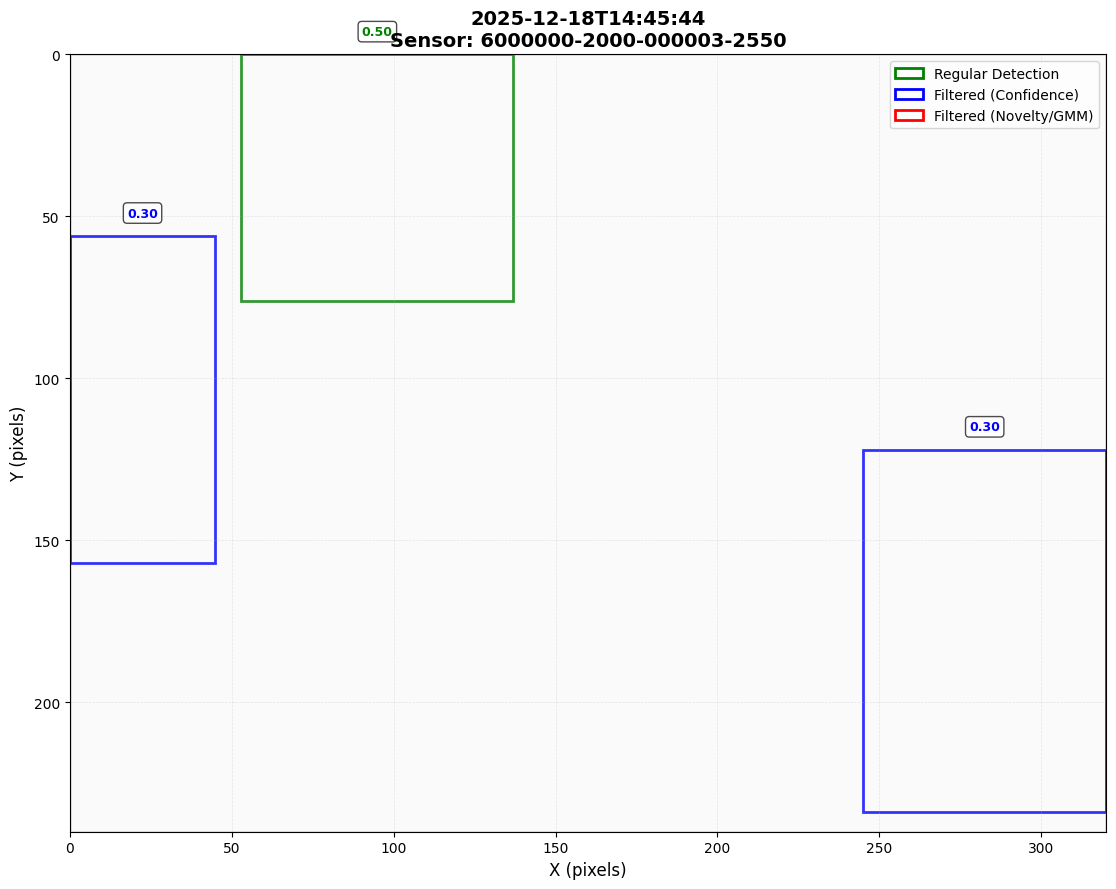

In [8]:
# Optional: Display one example inline
print("\n=== Example Visualization ===")

# Find a timestamp with multiple detections of different types
example_found = False

for sensor_id, timestamps_data in sensor_data.items():
    if example_found:
        break
    
    for timestamp, detections in timestamps_data.items():
        if len(detections) >= 2:
            # Check if we have multiple types
            types = set(d['type'] for d in detections)
            if len(types) >= 2:
                print(f"Displaying example from {sensor_id} at {timestamp}")
                
                fig, ax = plt.subplots(figsize=(12, 9))
                
                # Set up image coordinate system
                ax.set_xlim(0, IMAGE_WIDTH)
                ax.set_ylim(IMAGE_HEIGHT, 0)
                ax.set_aspect('equal')
                ax.set_xlabel('X (pixels)', fontsize=12)
                ax.set_ylabel('Y (pixels)', fontsize=12)
                ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
                ax.set_title(f'{timestamp}\nSensor: {sensor_id}', fontsize=14, fontweight='bold')
                
                # Background
                bg_rect = patches.Rectangle((0, 0), IMAGE_WIDTH, IMAGE_HEIGHT, 
                                          linewidth=2, edgecolor='black', 
                                          facecolor='lightgray', alpha=0.1)
                ax.add_patch(bg_rect)
                
                # Draw detections
                for detection in detections:
                    det_type = detection['type']
                    box = detection['box']
                    color = COLORS.get(det_type, 'yellow')
                    
                    rect = patches.Rectangle(
                        (box['x'], box['y']), box['w'], box['h'],
                        linewidth=2, edgecolor=color, facecolor='none', alpha=0.8
                    )
                    ax.add_patch(rect)
                    
                    if 'confidence' in detection:
                        conf = detection['confidence']
                        ax.text(box['x'] + box['w']/2, box['y'] - 5, f'{conf:.2f}', 
                               color=color, fontsize=9, fontweight='bold',
                               ha='center', va='bottom',
                               bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
                
                # Legend
                legend_elements = [
                    patches.Patch(facecolor='none', edgecolor='green', linewidth=2, label='Regular Detection'),
                    patches.Patch(facecolor='none', edgecolor='blue', linewidth=2, label='Filtered (Confidence)'),
                    patches.Patch(facecolor='none', edgecolor='red', linewidth=2, label='Filtered (Novelty/GMM)')
                ]
                ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
                
                plt.tight_layout()
                plt.show()
                
                example_found = True
                break

if not example_found:
    print("No suitable example found with multiple detection types")

In [9]:
# Summary statistics
print("\n=== Visualization Summary ===")

for sensor_id in SENSOR_IDS:
    output_dir = output_base_dir / sensor_id
    if output_dir.exists():
        image_files = list(output_dir.glob('*.png'))
        print(f"\n{sensor_id}:")
        print(f"  Images saved: {len(image_files)}")
        print(f"  Directory: {output_dir}")
        
        if image_files:
            # Show date range from filenames
            filenames = sorted([f.stem for f in image_files])
            print(f"  Time range: {filenames[0]} to {filenames[-1]}")


=== Visualization Summary ===

6000000-2000-000003-2550:
  Images saved: 434
  Directory: 2025-12-19_10-50-09/visualizations/6000000-2000-000003-2550
  Time range: 2025-12-18_14-45-20 to 2025-12-19_10-37-30

6000000-2000-000009-2550:
  Images saved: 906
  Directory: 2025-12-19_10-50-09/visualizations/6000000-2000-000009-2550
  Time range: 2025-12-18_15-17-37 to 2025-12-19_10-47-59
